# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.


**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).


## Equipo

- Alumno 1 :Norberto Narvaez
- Alumno 2 :


## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.


In [1]:
# TO-DO: completar con la URL de tu fork.
# Repo privado: https://<TOKEN>@github.com/<usuario>/tuia-dog-recognition-app.git
#REPO_URL = "https://github.com/<usuario>/tuia-dog-recognition-app.git"

#!git clone $REPO_URL proyecto
#%cd proyecto

## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.


In [2]:
#!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.


In [3]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data\dataset
GPU disponible: False


## 4. Descargar el dataset


In [4]:
!python scripts/download_dataset.py
!ls data/dataset

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\dogs.csv
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\test
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\train
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\valid
Dataset disponible en C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset


"ls" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


## 5. Descripción del dataset

TO-DO:

- Cantidad de razas, imágenes por raza en cada split, formato, resolución y licencia de uso.
- Cómo están encuadradas las imágenes, comparado con los recortes de YOLO que va a recibir el
  clasificador en la Etapa 3.
- Limitaciones del dataset (razas parecidas, sesgos, etc.) y cómo pueden afectar los resultados.


In [5]:
## TO-DO: descripción del dataset.
import pandas as pd
from PIL import Image

DATASET = settings.dataset_path
SPLITS = ["train", "valid", "test"]

# 1. Una fila por archivo: split, raza (= nombre de la carpeta), ruta y extensión
rows = []
for split in SPLITS:
    for breed_dir in sorted(p for p in (DATASET / split).iterdir() if p.is_dir()):
        for f in sorted(breed_dir.iterdir()):
            if f.is_file():
                rows.append({"split": split, "breed": breed_dir.name, "path": f, "ext": f.suffix.lower()})
df = pd.DataFrame(rows)


# 2. Resolución, modo de color y formato (PIL lee solo el encabezado, es rápido)
def leer_info(path):
    try:
        with Image.open(path) as im:
            return im.width, im.height, im.mode, im.format
    except Exception:
        return None, None, None, None  # no se pudo abrir: lo revisamos en la sección 7


df[["width", "height", "mode", "format"]] = df["path"].apply(lambda p: pd.Series(leer_info(p)))

# 3. Resumen
razas = {s: set(df.loc[df.split == s, "breed"]) for s in SPLITS}
print("Total de archivos:", len(df))
print("Razas por split:", {s: len(r) for s, r in razas.items()})
print("¿Mismas razas en los 3 splits?:", razas["train"] == razas["valid"] == razas["test"])
print("\nImágenes por split:\n", df["split"].value_counts().reindex(SPLITS).to_string())
print("\nExtensiones:\n", df["ext"].value_counts().to_string())
print("\nFormato / modo de color:\n", df.groupby(["format", "mode"], dropna=False).size().to_string())
print("\nResoluciones más frecuentes (ancho x alto):\n", df.groupby(["width", "height"], dropna=False).size().sort_values(ascending=False).head(5).to_string())
print("\nArchivos que no se pudieron abrir:", df["width"].isna().sum())

Total de archivos: 9346
Razas por split: {'train': 70, 'valid': 70, 'test': 70}
¿Mismas razas en los 3 splits?: False

Imágenes por split:
 split
train    7946
valid     700
test      700

Extensiones:
 ext
.jpg    9346

Formato / modo de color:
 format  mode
JPEG    RGB     9346

Resoluciones más frecuentes (ancho x alto):
 width  height
224    224       9346

Archivos que no se pudieron abrir: 0


In [6]:
# Qué razas aparecen en un split y no en otro.
# repr() muestra el nombre entre comillas, así se ven los espacios invisibles.
for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    solo_a = sorted(razas[a] - razas[b])
    solo_b = sorted(razas[b] - razas[a])
    if solo_a or solo_b:
        print(f"{a} vs {b}")
        print(f"   solo en {a}: {[repr(x) for x in solo_a]}")
        print(f"   solo en {b}: {[repr(x) for x in solo_b]}")

train vs valid
   solo en train: ["'American Spaniel'"]
   solo en valid: ["'American  Spaniel'"]
valid vs test
   solo en valid: ["'American  Spaniel'"]
   solo en test: ["'American Spaniel'"]


## 6. Análisis exploratorio (EDA)

TO-DO:

- Distribución de clases: imágenes por raza en cada split (gráfico y estadísticas). Desbalance.
- Resoluciones, relación de aspecto, canales, formatos y archivos corruptos.
- Grilla de ejemplos por raza, incluyendo pares de razas fáciles de confundir.
- Variaciones: iluminación, pose, fondo, oclusiones y cantidad de perros por imagen.


In [7]:
# Corrección de etiquetas: 'American  Spaniel' (doble espacio, solo en valid) -> 'American Spaniel'
df["breed_folder"] = df["breed"]                                  # nombre real de la carpeta
df["breed"] = df["breed_folder"].map(lambda s: " ".join(s.split()))  # colapsa espacios repetidos

razas = {s: set(df.loc[df.split == s, "breed"]) for s in SPLITS}
print("¿Mismas razas en los 3 splits?:", razas["train"] == razas["valid"] == razas["test"])
print("Cantidad de razas:", df["breed"].nunique())

¿Mismas razas en los 3 splits?: True
Cantidad de razas: 70


,mean,median,min,max,max/min
split,,,,,
train,113.5,111.5,65.0,198.0,3.05
valid,10.0,10.0,10.0,10.0,1.00
test,10.0,10.0,10.0,10.0,1.00


Razas con MENOS imágenes en train:


split,train,valid,test
breed,,,
American Hairless,65,10,10
Saint Bernard,78,10,10
Newfoundland,78,10,10
Yorkie,78,10,10
Boston Terrier,79,10,10


Razas con MÁS imágenes en train:


split,train,valid,test
breed,,,
Shih-Tzu,198,10,10
Lhasa,187,10,10
Labrador,161,10,10
Basset,159,10,10
Scotch Terrier,150,10,10


Imágenes por raza en valid (valores distintos): [np.int64(10)]
Imágenes por raza en test  (valores distintos): [np.int64(10)]


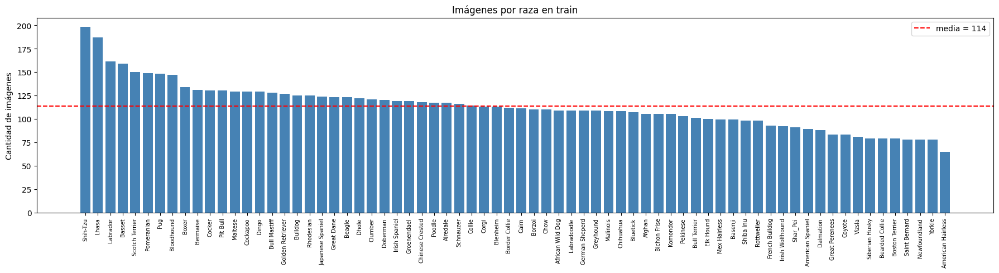


Si una raza tiene accuracy real de 0.90 
  n =  10: entre 0.60 y 0.98
  n =  30: entre 0.74 y 0.97
  n = 100: entre 0.83 y 0.94


In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Tabla raza x split: cuántas imágenes tiene cada raza en cada split
conteo = pd.crosstab(df["breed"], df["split"])[SPLITS]

stats = conteo.agg(["mean", "median", "min", "max"]).T.round(1)
stats["max/min"] = (conteo.max() / conteo.min()).round(2)
display(stats)

print("Razas con MENOS imágenes en train:")
display(conteo.sort_values("train").head(5))
print("Razas con MÁS imágenes en train:")
display(conteo.sort_values("train", ascending=False).head(5))
print("Imágenes por raza en valid (valores distintos):", sorted(conteo["valid"].unique()))
print("Imágenes por raza en test  (valores distintos):", sorted(conteo["test"].unique()))

orden = conteo["train"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(18, 5))
ax.bar(orden.index, orden.values, color="steelblue")
ax.axhline(orden.mean(), color="red", ls="--", label=f"media = {orden.mean():.0f}")
ax.set_title("Imágenes por raza en train")
ax.set_ylabel("Cantidad de imágenes")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend()
plt.tight_layout()
plt.show()


def wilson(p, n, z=1.96):
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen


print("\nSi una raza tiene accuracy real de 0.90 ")
for n in [10, 30, 100]:
    lo, hi = wilson(0.9, n)
    print(f"  n = {n:>3}: entre {lo:.2f} y {hi:.2f}")

**Conclusiones 6.1**

- **Train:** 7946 imágenes, 113,5 por raza en promedio (mediana 111,5), con un mínimo de 65 (American Hairless)
  y un máximo de 198 (Shih-Tzu). El desbalance es moderado: la raza mayor tiene unas 3 veces más imágenes
  que la menor (max/min = 3,05), y la mayoría está entre 80 y 150. No hay clases con muy pocas imágenes.
  En la Etapa 2 se evalúa si conviene compensarlo con class weights o weighted sampling.
- **Valid y test:** exactamente 10 imágenes por raza (700 cada uno), perfectamente balanceados. Las métricas
  macro de test no están sesgadas por el desbalance de train.
- **¿Alcanza el tamaño de valid/test?** Para las métricas globales sí (700 imágenes). Por raza no: con
  10 imágenes cada error mueve 10 puntos el recall de esa raza, y según el intervalo de Wilson (95 %) una
  raza con accuracy real de 0,90 podría medirse entre 0,60 y 0,98 (con 30 imágenes, 0,74–0,97; con 100,
  0,83–0,94). Por eso las métricas por raza se interpretan como indicativas, y este punto se retoma al
  decidir los splits (sección 11).


In [9]:
import cv2
from tqdm import tqdm
import cv2
import numpy as np
from tqdm import tqdm

def stats_imagen(path):
    """Abre la imagen con OpenCV (igual que la app) y calcula métricas que usamos en 6.2, 6.4 y 7."""
    img = cv2.imread(str(path))  # BGR uint8; devuelve None si no la puede decodificar
    if img is None:
        return {"cv2_ok": False, "casi_gris": np.nan, "brillo": np.nan, "contraste": np.nan, "nitidez": np.nan}
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = cv2.split(img.astype(np.int16))
    dif_canales = max(np.abs(b - g).mean(), np.abs(g - r).mean())
    return {
        "cv2_ok": True,
        "casi_gris": dif_canales < 2,                             # canales casi iguales: foto en blanco y negro guardada como RGB
        "brillo": gray.mean(),                                    # 0 = negro, 255 = blanco
        "contraste": gray.std(),                                  # desvío de los grises: bajo = imagen "plana"
        "nitidez": cv2.Laplacian(gray, cv2.CV_64F).var(),         # varianza del Laplaciano: baja = borrosa
    }


tqdm.pandas(desc="Analizando imágenes")
df = df.join(df["path"].progress_apply(lambda p: pd.Series(stats_imagen(p))))

print("Resoluciones distintas:", df.groupby(["width", "height"]).ngroups)
print("Relación de aspecto (ancho/alto):", (df["width"] / df["height"]).unique())
print("Modo de color según PIL:", df["mode"].value_counts().to_dict())
print("Legibles por OpenCV:", int(df["cv2_ok"].sum()), "de", len(df))
print("En escala de grises guardadas como RGB:", int(df["casi_gris"].sum()))
display(pd.crosstab(df["breed"], df["split"], values=df["casi_gris"], aggfunc="sum")
          .loc[lambda t: t.sum(axis=1) > 0])

Analizando imágenes: 100%|██████████| 9346/9346 [01:00<00:00, 155.00it/s]

Resoluciones distintas: 1
Relación de aspecto (ancho/alto): [1.]
Modo de color según PIL: {'RGB': 9346}
Legibles por OpenCV: 9346 de 9346
En escala de grises guardadas como RGB: 58


split,test,train,valid
breed,,,
Beagle,0,1,0
Bearded Collie,0,2,0
Bichon Frise,0,1,0
Bluetick,1,0,0
Border Collie,0,1,0
Borzoi,1,2,1
Boston Terrier,0,4,1
Bulldog,0,1,0
Chinese Crested,0,2,0


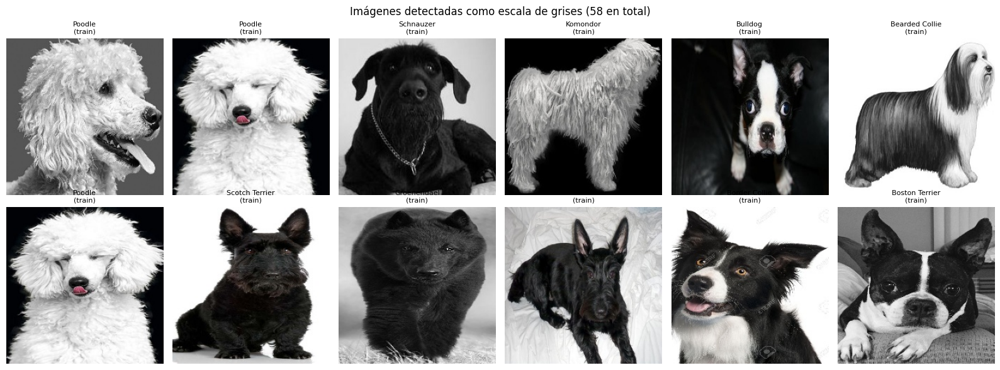

In [10]:
import matplotlib.pyplot as plt

grises = df[df["casi_gris"] == True]
muestra = grises.sample(min(12, len(grises)), random_state=0)

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, muestra.iterrows()):
    img = cv2.imread(str(row["path"]))[:, :, ::-1]  # BGR -> RGB: matplotlib espera RGB
    ax.imshow(img)
    ax.set_title(f"{row['breed']}\n({row['split']})", fontsize=8)
fig.suptitle(f"Imágenes detectadas como escala de grises ({len(grises)} en total)")
plt.tight_layout()
plt.show()

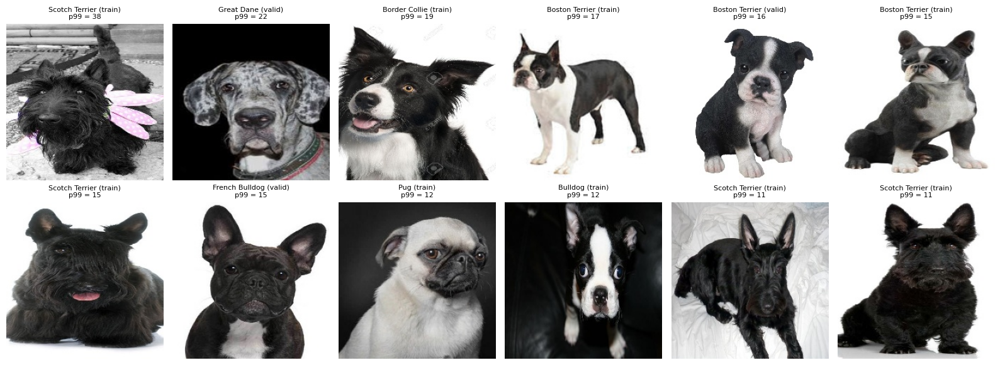

count    58.0
mean      5.5
std       7.6
min       0.0
25%       0.0
50%       0.0
75%      10.0
max      38.0
Name: p99_dif, dtype: float64


In [11]:
def p99_dif_canales(path):
    """Percentil 99 de la diferencia entre canales por píxel: sube si hay aunque sea una zona chica con color."""
    b, g, r = cv2.split(cv2.imread(str(path)).astype(np.int16))
    dif = np.maximum(np.abs(b - g), np.abs(g - r))
    return float(np.percentile(dif, 99))


cand = df["casi_gris"] == True
df.loc[cand, "p99_dif"] = df.loc[cand, "path"].map(p99_dif_canales)

# Las 12 candidatas con MÁS color: acá deberían aparecer los falsos positivos
top = df.loc[cand].sort_values("p99_dif", ascending=False).head(12)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, top.iterrows()):
    ax.imshow(cv2.imread(str(row["path"]))[:, :, ::-1])
    ax.set_title(f"{row['breed']} ({row['split']})\np99 = {row['p99_dif']:.0f}", fontsize=8)
plt.tight_layout()
plt.show()

print(df.loc[cand, "p99_dif"].describe().round(1))

In [12]:
print(df.loc[cand, "p99_dif"].round(0).value_counts().sort_index().to_string())

p99_dif
0.0     30
2.0      2
4.0      1
5.0      1
6.0      3
9.0      4
10.0     5
11.0     2
12.0     2
15.0     3
16.0     1
17.0     1
19.0     1
22.0     1
38.0     1


**Conclusiones 6.2**

- **Resolución:** las 9346 imágenes miden 224×224 (relación de aspecto 1). El autor las redimensionó
  al publicar el dataset, por lo que se perdió la relación de aspecto original y algunas pueden estar
  deformadas. Consecuencias: un filtro por resolución mínima no descarta ninguna imagen, y el cambio de
  dominio aparece en la Etapa 3, donde los recortes de YOLO tienen tamaños y proporciones variables
  (se decide cómo tratarlos en la sección 9).
- **Formato y lectura:** todas son JPEG en modo RGB y OpenCV (la misma librería que usa la app)
  decodifica las 9346.
- **Escala de grises:** PIL informa todas como RGB, pero algunas son fotos en blanco y negro con los tres
  canales iguales. Un primer criterio (diferencia media entre canales < 2) marcó 58, pero al inspeccionarlas
  aparecieron falsos positivos: perros blancos y negros fotografiados a color, donde el color se limita a
  ojos o lengua y casi no mueve el promedio. Se reemplazó por el percentil 99 de la diferencia por píxel:
  la distribución tiene un único corte claro entre 0 (30 imágenes) y 2, así que se consideran en escala de
  grises las 30 con p99 = 0. Representan el 0,3 % del dataset, están repartidas entre razas (ninguna tiene
  más de 4) y **no se descartan**: son fotos válidas y ya tienen 3 canales. Para que el modelo no dependa
  únicamente del color, en la sección 10 se evalúa agregar conversión a grises aleatoria con baja
  probabilidad como data augmentation.
- **Hallazgos para la sección 7:** la inspección mostró un posible duplicado dentro de train (dos fotos
  iguales de Poodle), una posible etiqueta errónea (una imagen de "Bulldog" que parece un Boston Terrier)
  e imágenes con marcas de agua de bancos de fotos, que evidencian el origen web del dataset.


### 6.3 Ejemplos por raza y pares fáciles de confundir


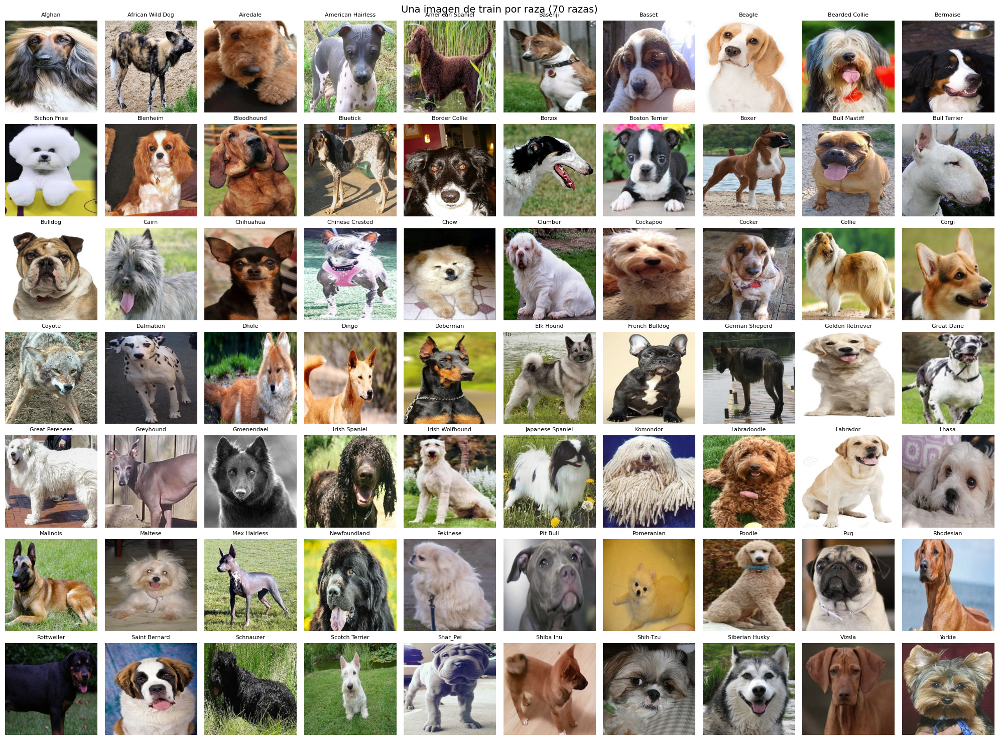

In [13]:
import random

random.seed(42)
razas_ordenadas = sorted(df["breed"].unique())
train_df = df[df["split"] == "train"]

fig, axes = plt.subplots(7, 10, figsize=(20, 15))
for ax, raza in zip(axes.flat, razas_ordenadas):
    fila = train_df[train_df["breed"] == raza].sample(1, random_state=42).iloc[0]
    ax.imshow(cv2.imread(str(fila["path"]))[:, :, ::-1])
    ax.set_title(raza, fontsize=8)
    ax.axis("off")
fig.suptitle("Una imagen de train por raza (70 razas)", fontsize=14)
plt.tight_layout()
plt.show()

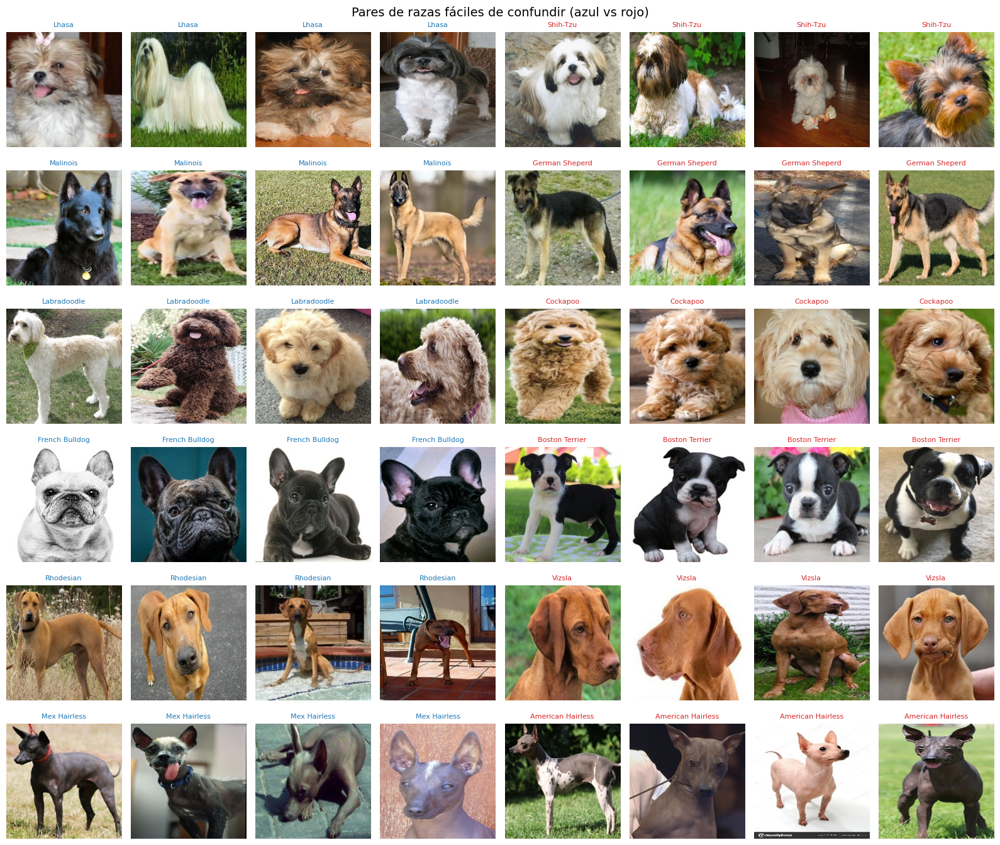

In [14]:
PARES = [
    ("Lhasa", "Shih-Tzu"),
    ("Malinois", "German Sheperd"),
    ("Labradoodle", "Cockapoo"),
    ("French Bulldog", "Boston Terrier"),
    ("Rhodesian", "Vizsla"),
    ("Mex Hairless", "American Hairless"),
]
faltan = [r for par in PARES for r in par if r not in razas_ordenadas]
assert not faltan, f"Nombres que no existen en el dataset: {faltan}"

N = 4
fig, axes = plt.subplots(len(PARES), 2 * N, figsize=(2 * N * 2, len(PARES) * 2.3))
for fila_ax, (a, b) in zip(axes, PARES):
    imgs = list(train_df[train_df["breed"] == a].sample(N, random_state=0)["path"]) + \
           list(train_df[train_df["breed"] == b].sample(N, random_state=0)["path"])
    for i, (ax, p) in enumerate(zip(fila_ax, imgs)):
        ax.imshow(cv2.imread(str(p))[:, :, ::-1])
        ax.set_title(a if i < N else b, fontsize=8, color="tab:blue" if i < N else "tab:red")
        ax.axis("off")
fig.suptitle("Pares de razas fáciles de confundir (azul vs rojo)", fontsize=14)
plt.tight_layout()
plt.show()

Resultados de YOLO leídos de output\yolo_eda.csv
Imágenes sin resultado de YOLO (debería ser 0): 0

Perros detectados por imagen:


split,train,valid,test
n_perros,,,
0,1308,102,100
1,6604,597,597
2,33,1,3
3 o más,1,0,0


Imágenes con al menos una persona: 249

Razas con más imágenes SIN perro detectado (train):


breed
Komondor            87
Dhole               72
Irish Spaniel       67
Coyote              62
African Wild Dog    58
Bichon Frise        42
Poodle              42
Groenendael         37
Dingo               37
Irish Wolfhound     34
dtype: int64

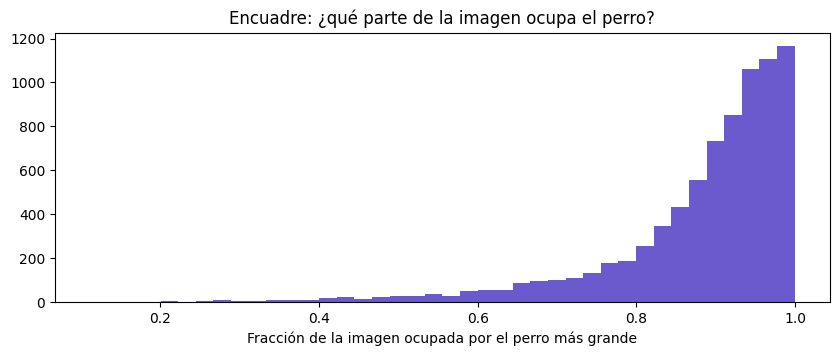

In [15]:
from ultralytics import YOLO

CACHE = settings.output_path / "yolo_eda.csv"   # output/ está en el .gitignore
DOG, PERSON = int(settings.yolo_dog_class_id), 0
LOTE = 32  # imágenes por llamada a YOLO: una lista entera se procesa como un único lote y no entra en RAM

if CACHE.exists():
    yolo_df = pd.read_csv(CACHE)
    print("Resultados de YOLO leídos de", CACHE)
else:
    yolo = YOLO(str(settings.model_path / "yolov8n.pt"))  # se descarga en models/ la primera vez
    filas = []
    paths = df["path"].astype(str).tolist()
    for i in tqdm(range(0, len(paths), LOTE), desc="YOLO (lotes)"):
        for r in yolo.predict(paths[i:i + LOTE], imgsz=320, conf=0.25, verbose=False):
            cls = r.boxes.cls.int().tolist()
            confs = r.boxes.conf.tolist()
            cajas = r.boxes.xyxy.tolist()
            perros = [(c, b) for k, c, b in zip(cls, confs, cajas) if k == DOG]
            alto, ancho = r.orig_shape
            area_max = max(((b[2] - b[0]) * (b[3] - b[1]) for _, b in perros), default=0) / (alto * ancho)
            filas.append({
                "path_str": r.path,
                "n_perros": len(perros),
                "conf_perro": max((c for c, _ in perros), default=0.0),
                "n_personas": cls.count(PERSON),
                "area_perro": area_max,
            })
    yolo_df = pd.DataFrame(filas)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    yolo_df.to_csv(CACHE, index=False)

df["path_str"] = df["path"].astype(str)
df = df.drop(columns=[c for c in ["n_perros", "conf_perro", "n_personas", "area_perro"] if c in df.columns])
df = df.merge(yolo_df, on="path_str", how="left")
print("Imágenes sin resultado de YOLO (debería ser 0):", int(df["n_perros"].isna().sum()))

print("\nPerros detectados por imagen:")
display(pd.crosstab(df["n_perros"].clip(upper=3), df["split"])[SPLITS].rename(index={3: "3 o más"}))
print(f"Imágenes con al menos una persona: {int((df['n_personas'] > 0).sum())}")
print("\nRazas con más imágenes SIN perro detectado (train):")
display(df[(df["split"] == "train") & (df["n_perros"] == 0)].groupby("breed").size().sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(df.loc[df["n_perros"] > 0, "area_perro"], bins=40, color="slateblue")
ax.set_xlabel("Fracción de la imagen ocupada por el perro más grande")
ax.set_title("Encuadre: ¿qué parte de la imagen ocupa el perro?")
plt.show()

YOLO sin perro: 100%|██████████| 48/48 [00:54<00:00,  1.13s/it]

¿Qué detecta YOLO en las imágenes sin perro? (clase con mayor confianza)


yolo_clase
bear          342
horse         267
cat           206
sheep         187
cow           124
teddy bear    123
bird          115
giraffe        69
person         41
dog            15
Name: count, dtype: int64


Con umbral 0.05, ¿aparece 'dog'?: 10% de las imágenes


breed
Komondor                 {'horse': 44, 'sheep': 28, 'bear': 19}
Dhole                      {'cat': 24, 'horse': 21, 'bear': 20}
Irish Spaniel       {'bear': 37, 'teddy bear': 18, 'sheep': 12}
Coyote                     {'cat': 15, 'sheep': 15, 'bear': 13}
African Wild Dog           {'bear': 16, 'horse': 13, 'cow': 11}
Bichon Frise         {'teddy bear': 36, 'bird': 7, 'person': 5}
Name: 3 clases más vistas, dtype: object

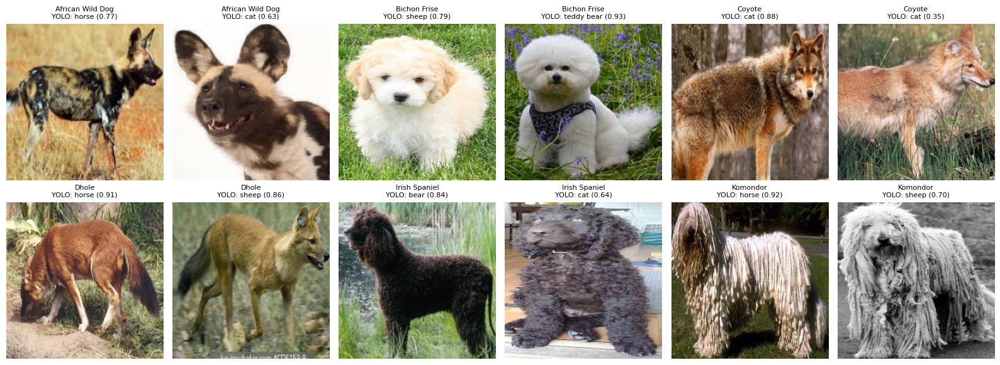

In [16]:
sin_perro = df[df["n_perros"] == 0]
yolo = YOLO(str(settings.model_path / "yolov8n.pt"))

filas = []
paths0 = sin_perro["path_str"].tolist()
for i in tqdm(range(0, len(paths0), LOTE), desc="YOLO sin perro"):
    for r in yolo.predict(paths0[i:i + LOTE], imgsz=320, conf=0.05, verbose=False):  # umbral bajo a propósito
        cls = r.boxes.cls.int().tolist()
        confs = r.boxes.conf.tolist()
        if cls:
            j = int(np.argmax(confs))
            mejor_clase, mejor_conf = r.names[cls[j]], confs[j]
        else:
            mejor_clase, mejor_conf = "(nada)", 0.0
        conf_dog = max((c for k, c in zip(cls, confs) if k == DOG), default=0.0)
        filas.append({"path_str": r.path, "yolo_clase": mejor_clase, "yolo_conf": mejor_conf, "conf_dog_baja": conf_dog})
vistas = pd.DataFrame(filas)

print("¿Qué detecta YOLO en las imágenes sin perro? (clase con mayor confianza)")
display(vistas["yolo_clase"].value_counts().head(10))

print(f"\nCon umbral 0.05, ¿aparece 'dog'?: {(vistas['conf_dog_baja'] > 0).mean():.0%} de las imágenes")

# Para las 6 razas con más fallas: qué clase ve YOLO
vistas = vistas.merge(df[["path_str", "breed"]], on="path_str")
top_razas = vistas["breed"].value_counts().head(6).index
display(pd.crosstab(vistas["breed"], vistas["yolo_clase"]).loc[top_razas]
          .apply(lambda f: f.sort_values(ascending=False).head(3).to_dict(), axis=1)
          .rename("3 clases más vistas"))

# Ejemplos visuales
muestra = vistas[vistas["breed"].isin(top_razas)].groupby("breed").head(2)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, muestra.iterrows()):
    ax.imshow(cv2.imread(row["path_str"])[:, :, ::-1])
    ax.set_title(f"{row['breed']}\nYOLO: {row['yolo_clase']} ({row['yolo_conf']:.2f})", fontsize=8)
plt.tight_layout()
plt.show()

**Conclusiones 6.4 — cantidad de perros, encuadre y comportamiento del detector**

Se pasó por todo el dataset el mismo detector de la Etapa 3 (YOLOv8n preentrenado en COCO, umbral 0,25).

- **Perros por imagen:** casi todas las imágenes tienen un solo perro; solo 38 (0,4 %) tienen dos o más.
  El dataset prácticamente no tiene escenas con varios perros: para validar la Etapa 3 en esos casos se
  usa el conjunto independiente.
- **Personas:** aparecen en 249 imágenes (2,7 %).
- **Encuadre medido:** en la mayoría de las imágenes la caja del perro ocupa entre el 80 % y el 100 % del
  cuadro. Un recorte de YOLO también es una caja ajustada al perro, por lo que en encuadre se parecen; el
  cambio de dominio real de la Etapa 3 está en la proporción (los recortes no son cuadrados), la resolución
  (perros lejanos dan recortes chicos) y los recortes que cortan partes del perro.
- **YOLO no detecta ningún perro en el 16,5 % de train (1308), 14,6 % de valid y 14,3 % de test**, y la
  falla depende de la raza: se concentra en cánidos salvajes (Dhole, Coyote, African Wild Dog, Dingo) y
  en razas de pelaje atípico (Komondor, Irish Spaniel, Bichon Frise, Poodle, Irish Wolfhound).
- **En esas imágenes YOLO sí ve un animal, pero con otra clase:** oso (342), caballo (267), gato (206),
  oveja (187), vaca (124), osito de peluche (123). Cada raza tiene una confusión típica (Komondor → caballo
  u oveja, Bichon Frise → osito de peluche, Irish Spaniel → oso). Bajar el umbral a 0,05 no lo resuelve:
  "dog" aparece solo en el 10 % de esos casos. Es una limitación del modelo, no del umbral.
- **Consecuencias:** (1) en el filtrado, "YOLO no detectó perro" **no** se usa para descartar imágenes:
  son fotos válidas y descartarlas eliminaría casi por completo razas como Komondor; (2) en la Etapa 3,
  estas razas pueden no llegar nunca al clasificador. Se analiza ahí la alternativa de aceptar otras
  clases de animales, considerando que las imágenes de gatos deben devolver una lista vacía.


## 7. Control de calidad y filtrado

TO-DO: reglas explícitas y reproducibles (archivos corruptos, baja resolución, imágenes borrosas o
con exposición extrema, duplicados y casi-duplicados dentro y entre splits, imágenes mal etiquetadas).
Reportar cuántas imágenes descarta cada regla y mostrar ejemplos de descartes.


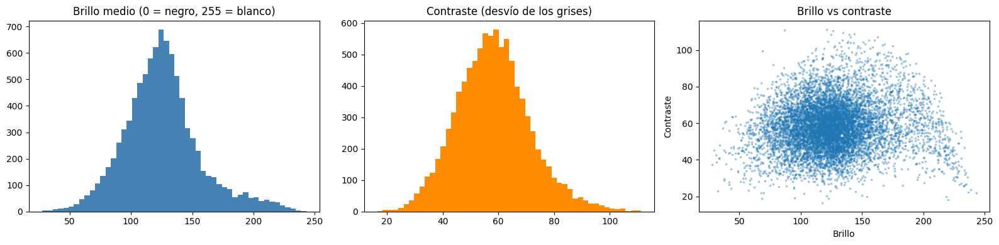

,brillo,contraste
count,9346.0,9346.0
mean,125.6,58.2
std,31.2,13.3
min,27.7,16.5
1%,58.2,29.8
5%,77.9,37.4
50%,123.8,57.8
95%,186.1,81.3
99%,217.2,94.3
max,243.0,111.3


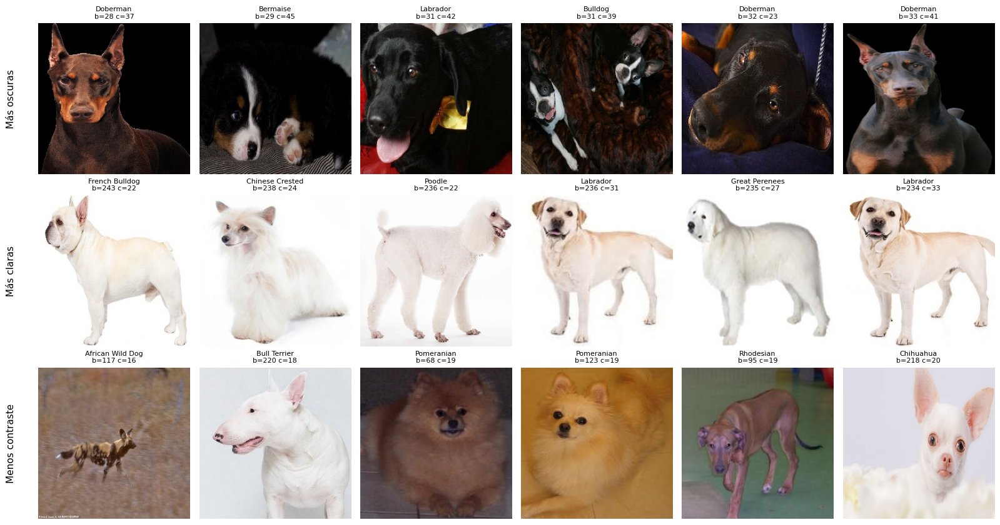


1 % más oscuro (94 imágenes) — razas más frecuentes:
breed
Doberman          10
Irish Spaniel      7
Bermaise           6
Rottweiler         6
Scotch Terrier     6

1 % más claro (94 imágenes) — razas más frecuentes:
breed
Chihuahua          14
Labrador           10
Chinese Crested     8
Poodle              8
Bichon Frise        6

1 % menos contraste (94 imágenes) — razas más frecuentes:
breed
Dhole               10
Pomeranian           8
African Wild Dog     4
Dingo                4
Labrador             4


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df["brillo"], bins=50, color="steelblue")
axes[0].set_title("Brillo medio (0 = negro, 255 = blanco)")
axes[1].hist(df["contraste"], bins=50, color="darkorange")
axes[1].set_title("Contraste (desvío de los grises)")
axes[2].scatter(df["brillo"], df["contraste"], s=3, alpha=0.3)
axes[2].set_xlabel("Brillo")
axes[2].set_ylabel("Contraste")
axes[2].set_title("Brillo vs contraste")
plt.tight_layout()
plt.show()

display(df[["brillo", "contraste"]].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1))

casos = {
    "Más oscuras": df.nsmallest(6, "brillo"),
    "Más claras": df.nlargest(6, "brillo"),
    "Menos contraste": df.nsmallest(6, "contraste"),
}
fig, axes = plt.subplots(3, 6, figsize=(16, 8.5))
for fila_ax, (titulo, sub) in zip(axes, casos.items()):
    for ax, (_, row) in zip(fila_ax, sub.iterrows()):
        ax.imshow(cv2.imread(str(row["path"]))[:, :, ::-1])
        ax.set_title(f"{row['breed']}\nb={row['brillo']:.0f} c={row['contraste']:.0f}", fontsize=8)
        ax.axis("off")
    fila_ax[0].text(-0.15, 0.5, titulo, transform=fila_ax[0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=11)
plt.tight_layout()
plt.show()

# ¿Qué razas dominan los extremos? (el 1 % más oscuro, el 1 % más claro y el 1 % con menos contraste)
for nombre, mask in {
    "1 % más oscuro": df["brillo"] < df["brillo"].quantile(0.01),
    "1 % más claro": df["brillo"] > df["brillo"].quantile(0.99),
    "1 % menos contraste": df["contraste"] < df["contraste"].quantile(0.01),
}.items():
    print(f"\n{nombre} ({int(mask.sum())} imágenes) — razas más frecuentes:")
    print(df.loc[mask, "breed"].value_counts().head(5).to_string())

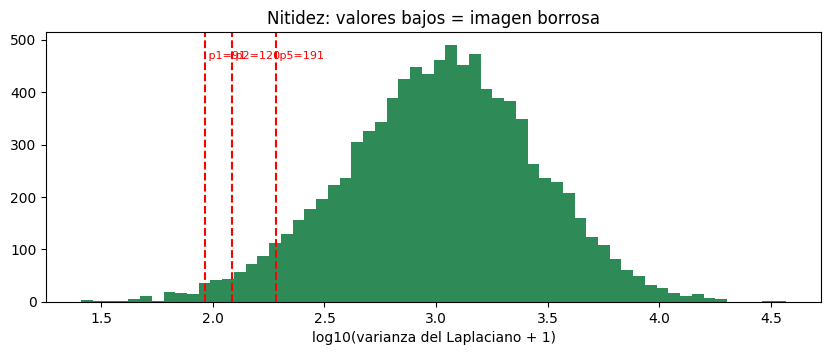

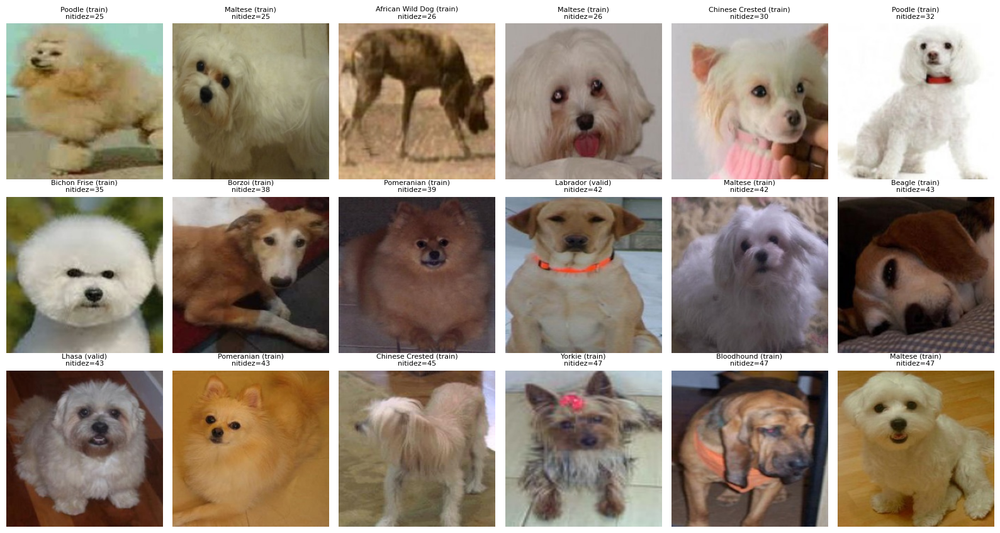

count     9346.0
mean      1643.9
std       1891.9
min         24.7
1%          91.1
2%         120.3
5%         190.7
25%        542.7
50%       1073.2
max      36934.6
Name: nitidez, dtype: float64


In [18]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(np.log10(df["nitidez"] + 1), bins=60, color="seagreen")
for p in [1, 2, 5]:
    v = df["nitidez"].quantile(p / 100)
    ax.axvline(np.log10(v + 1), color="red", ls="--")
    ax.text(np.log10(v + 1), ax.get_ylim()[1] * 0.9, f" p{p}={v:.0f}", color="red", fontsize=8)
ax.set_xlabel("log10(varianza del Laplaciano + 1)")
ax.set_title("Nitidez: valores bajos = imagen borrosa")
plt.show()

borrosas = df.nsmallest(18, "nitidez")
fig, axes = plt.subplots(3, 6, figsize=(16, 8.5))
for ax, (_, row) in zip(axes.flat, borrosas.iterrows()):
    ax.imshow(cv2.imread(str(row["path"]))[:, :, ::-1])
    ax.set_title(f"{row['breed']} ({row['split']})\nnitidez={row['nitidez']:.0f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

print(df["nitidez"].describe(percentiles=[0.01, 0.02, 0.05, 0.25, 0.5]).round(1))

In [19]:
for umbral in [50, 91, 120, 191]:
    cand = df[df["nitidez"] < umbral]
    print(f"\nnitidez < {umbral}: {len(cand)} imágenes ({len(cand) / len(df):.1%} del dataset)")
    top = cand["breed"].value_counts().head(5)
    # qué % de cada raza se perdería
    pct = (top / df["breed"].value_counts()[top.index] * 100).round(1)
    display(pd.DataFrame({"imágenes": top, "% de la raza": pct}))


nitidez < 50: 21 imágenes (0.2% del dataset)


,imágenes,% de la raza
breed,,
Maltese,4,2.7
Beagle,2,1.4
Chinese Crested,2,1.4
Pomeranian,2,1.2
Poodle,2,1.5



nitidez < 91: 94 imágenes (1.0% del dataset)


,imágenes,% de la raza
breed,,
Pekinese,9,7.3
Pomeranian,9,5.3
Maltese,8,5.4
Pit Bull,5,3.3
Chihuahua,4,3.1



nitidez < 120: 186 imágenes (2.0% del dataset)


,imágenes,% de la raza
breed,,
Maltese,15,10.1
Pomeranian,15,8.9
Pit Bull,14,9.3
Pekinese,13,10.6
Bichon Frise,10,8.0



nitidez < 191: 470 imágenes (5.0% del dataset)


,imágenes,% de la raza
breed,,
Pomeranian,36,21.3
Maltese,32,21.5
Bichon Frise,29,23.2
Pit Bull,25,16.7
Chihuahua,21,16.4


In [20]:
UMBRAL_NITIDEZ = 50  # elegido por el análisis de sesgo por raza (ver tabla anterior)
df["r3_borrosa"] = (df["nitidez"] < UMBRAL_NITIDEZ) & (df["split"] == "train")

print(f"Regla 3 (nitidez < {UMBRAL_NITIDEZ}, solo train): {int(df['r3_borrosa'].sum())} imágenes")
print("Máximo % perdido por una raza:",
      f"{(df[df['r3_borrosa']]['breed'].value_counts() / df[df['split'] == 'train']['breed'].value_counts()).max():.1%}")

Regla 3 (nitidez < 50, solo train): 19 imágenes
Máximo % perdido por una raza: 3.1%


**Regla 3 — Imágenes borrosas (varianza del Laplaciano)**

La varianza del Laplaciano mide la cantidad de bordes, no solo el desenfoque. La distribución no tiene un
corte natural, y al inspeccionar las imágenes con menor valor aparecieron tanto fotos realmente borrosas
como perros de pelaje blanco y liso, bien enfocados pero con pocos bordes. Se cuantificó qué porcentaje de
cada raza descartaría cada umbral candidato:

| Umbral     | Descarta | Raza más afectada                         |
| ---------- | -------- | ----------------------------------------- |
| p1 (≈ 91)  | 1 %      | Pekinese 7,3 %                            |
| p2 (≈ 120) | 2 %      | Pekinese / Maltese ≈ 10 %                 |
| p5 (≈ 191) | 5 %      | Bichon Frise, Maltese, Pomeranian 21–23 % |

Un umbral por percentil discriminaría sistemáticamente razas pequeñas de pelo claro, que además forman
un grupo de razas parecidas que el modelo necesita aprender a distinguir. Se elige un umbral conservador
de **50**, que elimina solo los casos extremos (ninguna raza pierde más del 2,7 %), y se aplica **solo
a train**: las fotos imperfectas son parte del mundo real y quitarlas de test inflaría las métricas.
Las imágenes moderadamente borrosas se conservan, en coherencia con el blur que se agrega como data
augmentation.


dHash: 100%|██████████| 9346/9346 [00:24<00:00, 378.45it/s]


Pares por distancia de Hamming:


col_0,test-test,train-test,train-train,train-valid,valid-test,valid-valid
dist,,,,,,
0,5,41,76,36,6,1
1,0,2,33,8,3,2
2,0,3,17,7,1,0
3,0,2,26,3,0,0
4,1,4,22,6,0,1
5,0,5,28,4,3,0
6,1,11,31,5,1,1
7,0,7,46,11,2,1
8,1,9,57,11,0,3


Pares con razas DISTINTAS: 550


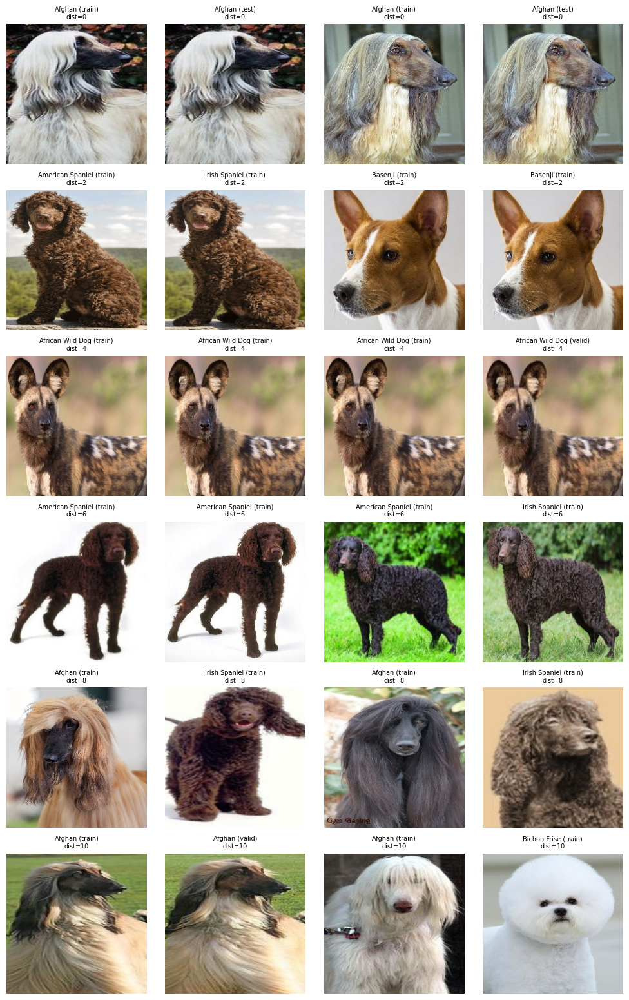

In [21]:
def dhash(path, size=8):
    """Hash perceptual de 64 bits: compara cada píxel con su vecino de la derecha en una versión 9x8 en grises."""
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (size + 1, size), interpolation=cv2.INTER_AREA)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return np.packbits(bits).view(">u8")[0]


tqdm.pandas(desc="dHash")
df["dhash"] = df["path"].progress_apply(dhash).astype(np.uint64)

# Comparamos todas contra todas en bloques (9346 x 9346 de una vez no entra en memoria)
H = df["dhash"].to_numpy()
MAX_DIST = 10
pares = []
for i0 in range(0, len(H), 512):
    d = np.bitwise_count(H[i0:i0 + 512, None] ^ H[None, :])  # distancia de Hamming
    ii, jj = np.nonzero(d <= MAX_DIST)
    m = (ii + i0) < jj                                       # cada par una sola vez, sin compararse consigo misma
    pares += zip(ii[m] + i0, jj[m], d[ii[m], jj[m]])

pares = pd.DataFrame(pares, columns=["i", "j", "dist"])
pares["split_i"], pares["split_j"] = df["split"].values[pares["i"]], df["split"].values[pares["j"]]
pares["raza_i"], pares["raza_j"] = df["breed"].values[pares["i"]], df["breed"].values[pares["j"]]

print("Pares por distancia de Hamming:")
display(pd.crosstab(pares["dist"], pares["split_i"] + "-" + pares["split_j"]))
print("Pares con razas DISTINTAS:", int((pares["raza_i"] != pares["raza_j"]).sum()))

# Ejemplos: 2 pares por cada distancia, para elegir el umbral
fig, axes = plt.subplots(len(range(0, MAX_DIST + 1, 2)), 4, figsize=(10, 2.6 * 6))
for fila, dist in zip(axes, range(0, MAX_DIST + 1, 2)):
    ej = pares[pares["dist"] == dist].head(2)
    for k in range(2):
        for ax in fila[2 * k:2 * k + 2]:
            ax.axis("off")
        if k < len(ej):
            p = ej.iloc[k]
            for ax, idx in zip(fila[2 * k:2 * k + 2], [p["i"], p["j"]]):
                ax.imshow(cv2.imread(str(df["path"].iloc[idx]))[:, :, ::-1])
                ax.set_title(f"{df['breed'].iloc[idx]} ({df['split'].iloc[idx]})\ndist={dist}", fontsize=7)
plt.tight_layout()
plt.show()

100%|██████████| 1154/1154 [00:02<00:00, 525.29it/s]

Correlación según la distancia de Hamming:


,count,min,50%,max
dist,,,,
0,165.0,0.858,1.000,1.000
1,48.0,0.834,0.978,1.000
2,28.0,0.879,0.949,0.996
3,31.0,0.836,0.948,0.984
4,34.0,0.665,0.910,0.982
5,40.0,0.652,0.899,0.975
6,50.0,0.502,0.844,0.982
7,67.0,0.098,0.800,0.951
8,81.0,0.328,0.677,0.932


Pares con razas DISTINTAS: 550


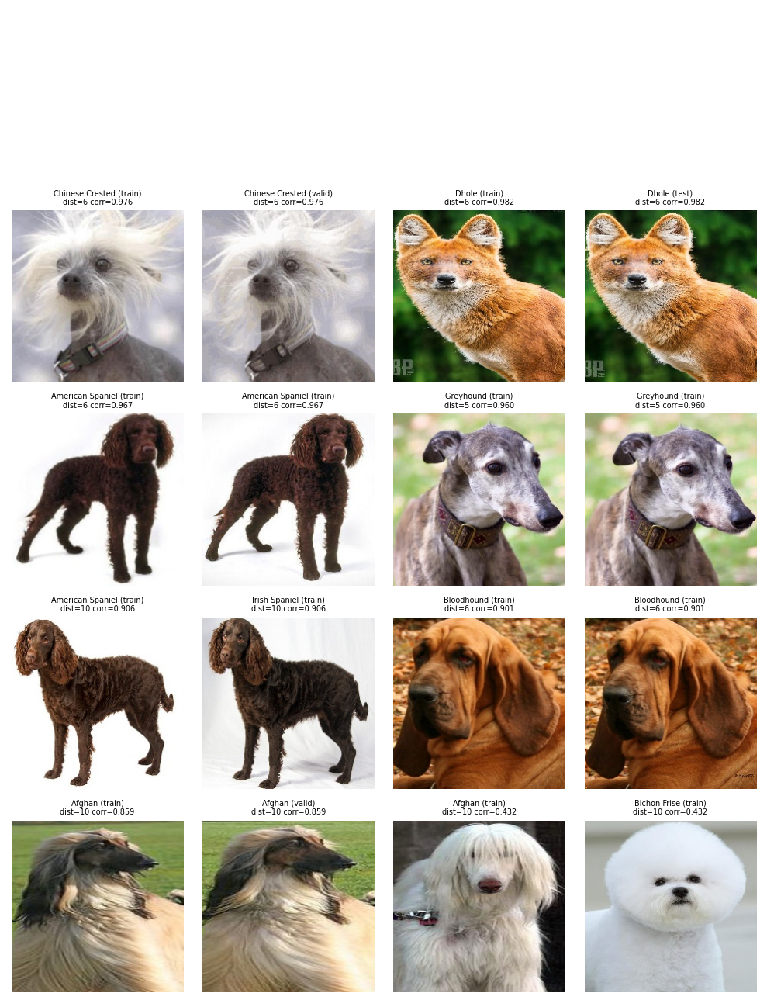

In [22]:
_cache = {}
def mini(idx, s=64):
    """Imagen reducida a 64x64 en grises, como vector (con caché para no releerla)."""
    if idx not in _cache:
        g = cv2.imread(str(df["path"].iloc[idx]), cv2.IMREAD_GRAYSCALE)
        _cache[idx] = cv2.resize(g, (s, s), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
    return _cache[idx]


pares["corr"] = [np.corrcoef(mini(i), mini(j))[0, 1] for i, j in tqdm(zip(pares["i"], pares["j"]), total=len(pares))]

print("Correlación según la distancia de Hamming:")
display(pares.groupby("dist")["corr"].describe()[["count", "min", "50%", "max"]].round(3))
print("Pares con razas DISTINTAS:", int((pares["raza_i"] != pares["raza_j"]).sum()))

# Ejemplos por franja de correlación (solo dist >= 5, que es la zona dudosa)
franjas = [(0.99, 1.01), (0.97, 0.99), (0.95, 0.97), (0.90, 0.95), (-1, 0.90)]
dudosos = pares[pares["dist"] >= 5]
fig, axes = plt.subplots(len(franjas), 4, figsize=(10, 2.6 * len(franjas)))
for fila, (lo, hi) in zip(axes, franjas):
    ej = dudosos[(dudosos["corr"] >= lo) & (dudosos["corr"] < hi)].head(2)
    for ax in fila:
        ax.axis("off")
    for k, (_, p) in enumerate(ej.iterrows()):
        for ax, idx in zip(fila[2 * k:2 * k + 2], [p["i"], p["j"]]):
            ax.imshow(cv2.imread(str(df["path"].iloc[idx]))[:, :, ::-1])
            ax.set_title(f"{df['breed'].iloc[idx]} ({df['split'].iloc[idx]})\ndist={p['dist']} corr={p['corr']:.3f}", fontsize=7)
plt.tight_layout()
plt.show()

In [23]:
UMBRAL_CORR = 0.90
df = df.reset_index(drop=True)  # para que la posición (i, j) coincida con el índice

dup = pares[(pares["dist"] == 0) | (pares["corr"] >= UMBRAL_CORR)]
print("Pares considerados duplicados:", len(dup))
display(pd.crosstab(dup["split_i"], dup["split_j"]))

# Agrupar en clusters: si A=B y B=C, las tres son la misma foto (union-find)
padre = list(range(len(df)))
def raiz(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]
        x = padre[x]
    return x
for i, j in zip(dup["i"], dup["j"]):
    padre[raiz(i)] = raiz(j)
df["cluster_dup"] = [raiz(k) for k in range(len(df))]

# De cada cluster se conserva una copia: prioridad test > valid > train
PRIORIDAD = {"test": 0, "valid": 1, "train": 2}
df["r5_duplicada"] = False
df["conflicto_etiqueta"] = False
for _, grupo in df[df.duplicated("cluster_dup", keep=False)].groupby("cluster_dup"):
    orden = grupo.assign(p=grupo["split"].map(PRIORIDAD)).sort_values(["p", "path_str"])
    df.loc[orden.index[1:], "r5_duplicada"] = True
    if grupo["breed"].nunique() > 1:
        df.loc[grupo.index, "conflicto_etiqueta"] = True

print("\nRegla 5 — copias descartadas por split:")
print(df[df["r5_duplicada"]]["split"].value_counts().to_string())
n_conf = df[df["conflicto_etiqueta"]]["cluster_dup"].nunique()
print(f"\nClusters con razas distintas (conflicto de etiqueta): {n_conf}")
display(df[df["conflicto_etiqueta"]].groupby("cluster_dup")["breed"].apply(lambda s: " / ".join(sorted(set(s))))
          .value_counts().rename("veces"))

Pares considerados duplicados: 327


split_j,test,train,valid
split_i,,,
test,5,0,0
train,61,187,59
valid,10,0,5



Regla 5 — copias descartadas por split:
split
train    270
valid     15
test       4

Clusters con razas distintas (conflicto de etiqueta): 5


breed
American Spaniel / Irish Spaniel    3
Border Collie / Collie              1
Cockapoo / Labradoodle              1
Name: veces, dtype: int64

duplicados

Se calculó un hash perceptual (dHash, 64 bits) de cada imagen y se buscaron todos los pares con distancia
de Hamming ≤ 10. La distancia sola no alcanza: entre 6 y 10 aparecen tanto la misma foto como fotos
distintas. Por eso cada par candidato se verificó con la correlación entre ambas imágenes reducidas a
64×64 en grises. Inspeccionando ejemplos por franja de correlación, por encima de 0,90 todos los pares
son la misma foto (recomprimida, recortada o con una firma). Se considera duplicado un par con
**dHash idéntico o correlación ≥ 0,90**. Limitación: la correlación píxel a píxel es sensible a
desplazamientos, por lo que algunas copias levemente corridas (correlación ≈ 0,86) no se detectan.

Resultado: **327 pares duplicados, 130 de ellos entre splits distintos** (61 train-test, 59 train-valid,
10 valid-test). Esto contradice lo que afirma el autor del dataset (que eliminó los duplicados entre
splits) y habría producido **fuga de datos**. Los duplicados se agrupan en clusters (si A=B y B=C, las
tres son la misma foto) y de cada cluster se conserva una sola copia, con prioridad test > valid > train,
para no modificar el conjunto de evaluación. Se descartan **289 imágenes: 270 de train, 15 de valid y
4 de test** (fotos repetidas dentro del propio test). Se aplica a todos los splits.


In [24]:
# Regla 1 — Corruptos: OpenCV (la misma librería que usa la app) no puede decodificarla
df["r1_corrupta"] = ~df["cv2_ok"].astype(bool)

# Regla 2 — Resolución menor al tamaño de entrada del modelo (IMAGE_SIZE)
MIN_LADO = settings.image_size
df["r2_baja_res"] = (df["width"] < MIN_LADO) | (df["height"] < MIN_LADO)

print(f"Regla 1 (corruptas): {int(df['r1_corrupta'].sum())}")
print(f"Regla 2 (lado < {MIN_LADO}px): {int(df['r2_baja_res'].sum())}")

Regla 1 (corruptas): 0
Regla 2 (lado < 224px): 0


Regla 6 (conflicto de etiqueta):
split
train    10


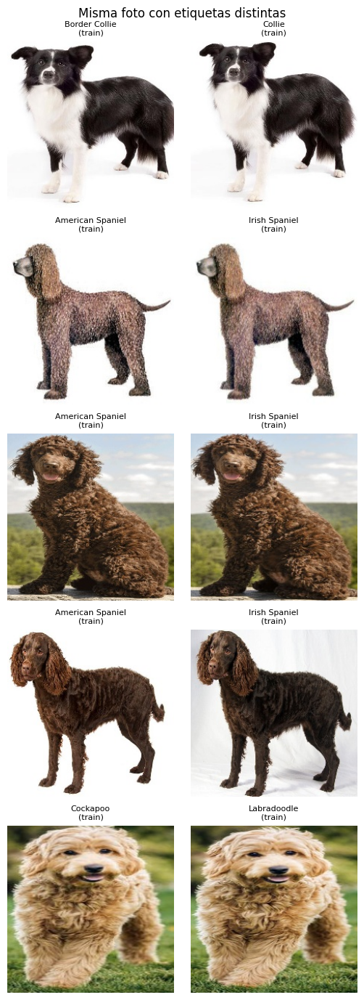

In [25]:
# Regla 6 — Conflicto de etiqueta: la misma foto aparece con dos razas distintas -> se descartan todas las copias
df["r6_mal_etiquetada"] = df["conflicto_etiqueta"]
print("Regla 6 (conflicto de etiqueta):")
print(df[df["r6_mal_etiquetada"]]["split"].value_counts().to_string())

# Ejemplos: cada cluster en conflicto, con sus etiquetas
conf = df[df["r6_mal_etiquetada"]].sort_values(["cluster_dup", "split"])
grupos = list(conf.groupby("cluster_dup"))
max_n = max(len(g) for _, g in grupos)
fig, axes = plt.subplots(len(grupos), max_n, figsize=(2.6 * max_n, 2.8 * len(grupos)), squeeze=False)
for fila, (_, g) in zip(axes, grupos):
    for ax in fila:
        ax.axis("off")
    for ax, (_, row) in zip(fila, g.iterrows()):
        ax.imshow(cv2.imread(str(row["path"]))[:, :, ::-1])
        ax.set_title(f"{row['breed']}\n({row['split']})", fontsize=8)
fig.suptitle("Misma foto con etiquetas distintas", fontsize=12)
plt.tight_layout()
plt.show()

In [26]:
# Si las reglas 3 y 4 no se crearon, se crean acá (solo usan columnas ya calculadas)
if "r3_borrosa" not in df.columns:
    df["r3_borrosa"] = (df["nitidez"] < 50) & (df["split"] == "train")
if "r4_exposicion" not in df.columns:
    df["r4_exposicion"] = (((df["brillo"] < 30) | (df["brillo"] > 225))
                           & (df["contraste"] < 20) & (df["split"] == "train"))

REGLAS = {
    "r1_corrupta": "1. Corrupta",
    "r2_baja_res": "2. Resolución < 224",
    "r3_borrosa": "3. Borrosa (solo train)",
    "r4_exposicion": "4. Exposición extrema (solo train)",
    "r5_duplicada": "5. Duplicada",
    "r6_mal_etiquetada": "6. Conflicto de etiqueta",
}

faltan = [c for c in REGLAS if c not in df.columns]
if faltan:
    print("Todavía faltan estas reglas:", faltan)
    print("r1/r2 -> celda de reglas 1 y 2 | r5 -> dhash, correlación y UMBRAL_CORR | r6 -> celda de la regla 6")
else:
    for col in REGLAS:
        df[col] = df[col].astype(bool)

    resumen = pd.DataFrame({
        nombre: df[df[col]]["split"].value_counts().reindex(SPLITS, fill_value=0)
        for col, nombre in REGLAS.items()
    }).T
    df["descartar"] = df[list(REGLAS)].any(axis=1)
    antes = df["split"].value_counts().reindex(SPLITS)
    total_desc = df[df["descartar"]]["split"].value_counts().reindex(SPLITS, fill_value=0)
    resumen.loc["Total descartadas (sin doble conteo)"] = total_desc
    resumen.loc["Antes del filtrado"] = antes
    resumen.loc["Después del filtrado"] = antes - total_desc
    resumen["total"] = resumen.sum(axis=1)
    display(resumen)

    limpio = df[~df["descartar"]]
    por_raza = pd.crosstab(limpio["breed"], limpio["split"])[SPLITS]
    print("Imágenes por raza después del filtrado:")
    display(por_raza.agg(["min", "median", "max"]).T)
    print("Razas que quedan con menos de 10 imágenes en valid o test:")
    display(por_raza[(por_raza["valid"] < 10) | (por_raza["test"] < 10)])

split,train,valid,test,total
1. Corrupta,0,0,0,0
2. Resolución < 224,0,0,0,0
3. Borrosa (solo train),19,0,0,19
4. Exposición extrema (solo train),0,0,0,0
5. Duplicada,270,15,4,289
6. Conflicto de etiqueta,10,0,0,10
Total descartadas (sin doble conteo),294,15,4,313
Antes del filtrado,7946,700,700,9346
Después del filtrado,7652,685,696,9033


Imágenes por raza después del filtrado:


,min,median,max
split,,,
train,63.0,107.5,190.0
valid,8.0,10.0,10.0
test,8.0,10.0,10.0


Razas que quedan con menos de 10 imágenes en valid o test:


split,train,valid,test
breed,,,
African Wild Dog,106,8,10
American Spaniel,84,9,10
Bichon Frise,96,8,10
Bulldog,121,9,10
Chinese Crested,110,9,10
Clumber,115,9,10
Cockapoo,119,10,9
Doberman,115,9,10
Greyhound,105,9,10


## 8. Conjunto independiente de evaluación

TO-DO: imágenes que no pertenezcan al dataset (internet o fotos propias), con las mismas razas que
las carpetas del dataset. Incluir imágenes con un perro (Etapas 1 y 2), escenas con varios perros u
otros objetos e imágenes sin perros (Etapa 3). Documentar fuente y licencia; no subirlas al repositorio.


In [27]:
IND = settings.dataset_path / "independent"   # data/dataset/* ya está en el .gitignore: no se sube al repo

RAZAS_IND = [
    "Lhasa", "Shih-Tzu", "Maltese", "Bichon Frise",
    "Labradoodle", "Cockapoo", "Malinois", "German Sheperd",
    "French Bulldog", "Boston Terrier", "Rhodesian", "Vizsla",
    "Collie", "Border Collie", "Labrador", "Golden Retriever",
    "Siberian Husky", "Beagle", "Pug", "Chihuahua", "Dalmation", "Komondor",
]
faltan = [r for r in RAZAS_IND if r not in razas_ordenadas]
assert not faltan, f"Nombres que no existen en el dataset: {faltan}"

for carpeta in RAZAS_IND + ["_escenas", "_sin_perros"]:
    (IND / carpeta).mkdir(parents=True, exist_ok=True)

FUENTES = IND / "fuentes.csv"
if not FUENTES.exists():
    pd.DataFrame(columns=["archivo", "raza", "tipo", "fuente_url", "autor", "licencia"]).to_csv(FUENTES, index=False)

print("Carpetas creadas en:", IND.resolve())

Carpetas creadas en: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\independent


In [28]:
import re
import time
import requests

API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "TUIA-TP2-dog-breeds/1.0 (trabajo práctico universitario)"}  # Wikimedia exige User-Agent
N_CANDIDATAS = 10  # bajamos el doble de lo necesario: después se eligen 5 por raza a mano
FORZAR_DESCARGA = False  # poner True solo para volver a descargar todo desde cero

# Términos de búsqueda en inglés correcto (los nombres del dataset tienen errores o están abreviados)
BUSQUEDA = {
    "Lhasa": "Lhasa Apso", "Shih-Tzu": "Shih Tzu dog", "Maltese": "Maltese dog", "Bichon Frise": "Bichon Frise",
    "Labradoodle": "Labradoodle", "Cockapoo": "Cockapoo", "Malinois": "Belgian Malinois",
    "German Sheperd": "German Shepherd dog", "French Bulldog": "French Bulldog", "Boston Terrier": "Boston Terrier",
    "Rhodesian": "Rhodesian Ridgeback", "Vizsla": "Vizsla dog", "Collie": "Rough Collie", "Border Collie": "Border Collie",
    "Labrador": "Labrador Retriever", "Golden Retriever": "Golden Retriever", "Siberian Husky": "Siberian Husky",
    "Beagle": "Beagle dog", "Pug": "Pug dog", "Chihuahua": "Chihuahua dog", "Dalmation": "Dalmatian dog",
    "Komondor": "Komondor",
}
EXTRAS = {  # carpeta: (tipo, búsquedas)
    "_escenas": ("escena", ["group of dogs playing", "people walking dogs park", "two dogs"]),
    "_sin_perros": ("sin_perro", ["domestic cat", "red fox", "sheep flock"]),  # oveja: YOLO confunde razas con ovejas
}


def buscar_commons(texto, n):
    """Devuelve hasta n imágenes de Wikimedia Commons con URL, autor y licencia."""
    params = {
        "action": "query", "format": "json", "generator": "search", "gsrnamespace": 6,
        "gsrsearch": f"filetype:bitmap {texto}", "gsrlimit": n * 2,
        "prop": "imageinfo", "iiprop": "url|extmetadata|mime", "iiurlwidth": 640,
    }
    paginas = requests.get(API, params=params, headers=HEADERS, timeout=30).json().get("query", {}).get("pages", {})
    resultados = []
    for p in paginas.values():
        info = p["imageinfo"][0]
        meta = info.get("extmetadata", {})
        licencia = meta.get("LicenseShortName", {}).get("value", "")
        if info.get("mime") not in ("image/jpeg", "image/png"):
            continue
        if not ("CC" in licencia or "Public domain" in licencia):
            continue  # solo licencias abiertas y documentables
        autor = re.sub(r"<[^>]+>", "", meta.get("Artist", {}).get("value", "")).strip()
        resultados.append({"url": info["thumburl"], "fuente_url": info["descriptionurl"], "autor": autor, "licencia": licencia})
    return resultados[:n]


def descargar(item, destino):
    """Descarga la imagen y la guarda como JPEG. Devuelve False si no se pudo decodificar."""
    datos = requests.get(item["url"], headers=HEADERS, timeout=30).content
    img = cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        return False
    cv2.imwrite(str(destino), img)
    return True


# Si ya se descargó antes, no se vuelve a descargar (así no se pierde la revisión manual)
ya_descargado = FUENTES.exists() and len(pd.read_csv(FUENTES)) > 0
if ya_descargado and not FORZAR_DESCARGA:
    print(f"Ya hay imágenes descargadas ({len(pd.read_csv(FUENTES))} en {FUENTES.name}): no se descarga de nuevo.")
    print("Para volver a descargar todo, poner FORZAR_DESCARGA = True.")
else:
    filas = []
    tareas = [(raza, raza, "limpia", [BUSQUEDA[raza]]) for raza in RAZAS_IND] + \
             [(carpeta, "", tipo, busquedas) for carpeta, (tipo, busquedas) in EXTRAS.items()]

    for carpeta, raza, tipo, busquedas in tqdm(tareas, desc="Descargando"):
        n_por_busqueda = N_CANDIDATAS if tipo == "limpia" else 7
        k = 0
        for texto in busquedas:
            for item in buscar_commons(texto, n_por_busqueda):
                k += 1
                nombre = f"{carpeta}/wm_{k:02d}.jpg"
                if descargar(item, IND / nombre):
                    filas.append({"archivo": nombre, "raza": raza, "tipo": tipo,
                                  **{c: item[c] for c in ["fuente_url", "autor", "licencia"]}})
                time.sleep(0.5)  # no saturar el servidor de Wikimedia

    pd.DataFrame(filas).to_csv(FUENTES, index=False)
    print(f"Descargadas: {len(filas)} imágenes. Fuentes guardadas en {FUENTES}")
    display(pd.DataFrame(filas)["tipo"].value_counts())

Ya hay imágenes descargadas (223 en fuentes.csv): no se descarga de nuevo.
Para volver a descargar todo, poner FORZAR_DESCARGA = True.


In [29]:
fuentes = pd.read_csv(FUENTES)
print("Candidatas por carpeta:")
display(fuentes["archivo"].str.split("/").str[0].value_counts().rename("imágenes"))

Candidatas por carpeta:


archivo
_sin_perros         21
_escenas            16
Cockapoo            10
German Sheperd      10
Border Collie       10
Golden Retriever    10
Siberian Husky      10
Beagle              10
Labradoodle          9
Malinois             9
Vizsla               9
Labrador             9
Pug                  9
Chihuahua            9
Dalmation            9
French Bulldog       8
Boston Terrier       8
Komondor             8
Shih-Tzu             7
Maltese              7
Bichon Frise         7
Lhasa                6
Rhodesian            6
Collie               6
Name: imágenes, dtype: int64

In [30]:
fuentes = pd.read_csv(FUENTES)

# 1) Quitar del CSV las imágenes que borraste en la revisión
existe = fuentes["archivo"].map(lambda a: (IND / a).exists())
print("Imágenes borradas en la revisión:", int((~existe).sum()))
fuentes = fuentes[existe].reset_index(drop=True)
fuentes.to_csv(FUENTES, index=False)

# 2) Avisar si hay imágenes en las carpetas que no figuran en el CSV (por ejemplo, fotos propias)
en_disco = {p.relative_to(IND).as_posix() for p in IND.rglob("*.jpg")}
sin_fuente = sorted(en_disco - set(fuentes["archivo"]))
print("Imágenes sin fuente en el CSV:", sin_fuente if sin_fuente else "ninguna")

print("\nImágenes finales por carpeta:")
display(fuentes["archivo"].str.split("/").str[0].value_counts().rename("imágenes"))

Imágenes borradas en la revisión: 0
Imágenes sin fuente en el CSV: ninguna

Imágenes finales por carpeta:


archivo
_sin_perros         21
_escenas            16
Cockapoo            10
German Sheperd      10
Border Collie       10
Golden Retriever    10
Siberian Husky      10
Beagle              10
Labradoodle          9
Malinois             9
Vizsla               9
Labrador             9
Pug                  9
Chihuahua            9
Dalmation            9
French Bulldog       8
Boston Terrier       8
Komondor             8
Shih-Tzu             7
Maltese              7
Bichon Frise         7
Lhasa                6
Rhodesian            6
Collie               6
Name: imágenes, dtype: int64

## 9. Preprocesamiento

TO-DO: definir y justificar el resize, la normalización y el orden de canales (la app entrega BGR).

⚠️ El mismo preprocesamiento debe usarse en las notebooks y en los servicios de la app:
encapsulalo en un módulo de `src/lib/` e importalo desde ambos lados.


In [31]:
import importlib
import lib.preprocessing as prep
importlib.reload(prep)

IMG = settings.image_size

# Verificación: el módulo devuelve un tensor 3x224x224 normalizado
ejemplo = cv2.imread(str(limpio.iloc[0]["path"]))
t = prep.to_tensor(prep.to_rgb_resized(ejemplo, IMG))
print("Entrada:", ejemplo.shape, "-> Salida:", tuple(t.shape))

# ¿Las estadísticas de train se parecen a las de ImageNet? (para justificar la normalización de la CNN propia)
muestra = limpio[limpio["split"] == "train"].sample(1000, random_state=0)
pix = np.stack([prep.to_rgb_resized(cv2.imread(str(p)), IMG) for p in muestra["path"]]) / 255.0
display(pd.DataFrame({"media train": pix.mean(axis=(0, 1, 2)), "media ImageNet": prep.IMAGENET_MEAN,
                      "desvío train": pix.std(axis=(0, 1, 2)), "desvío ImageNet": prep.IMAGENET_STD},
                     index=["R", "G", "B"]).round(3))

c:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Entrada: (224, 224, 3) -> Salida: (3, 224, 224)


,media train,media ImageNet,desvío train,desvío ImageNet
R,0.518,0.485,0.273,0.229
G,0.485,0.456,0.268,0.224
B,0.417,0.406,0.275,0.225


**Decisiones de preprocesamiento** (implementado en `src/lib/preprocessing.py` e importado desde las
notebooks y desde los servicios de la app, para que entrenamiento e inferencia usen exactamente el mismo
pipeline)

- **Orden de canales:** la app entrega imágenes BGR (OpenCV) y los modelos preentrenados esperan RGB:
  la conversión se hace dentro del módulo, así ningún servicio puede olvidarla.
- **Resize directo a 224×224** (sin recorte ni padding): las imágenes del dataset ya vienen
  redimensionadas a un cuadrado por el autor, por lo que el modelo aprende con esa deformación. Aplicar
  lo mismo a los recortes de YOLO mantiene la coherencia entre entrenamiento e inferencia. El center
  crop cortaría partes del perro (los recortes de YOLO son cajas ajustadas al animal) y el padding
  agregaría bordes negros que el modelo nunca vio al entrenar.
- **Normalización con las estadísticas de ImageNet para los tres modelos:** es obligatoria para los
  preentrenados. Para la CNN propia se compararon con las de train (muestra de 1000 imágenes): train es
  levemente más claro (media ≈ 0,52 / 0,49 / 0,42 vs 0,49 / 0,46 / 0,41) y con algo más de variación
  (desvío ≈ 0,27 vs 0,23), consistente con la presencia de perros oscuros y claros sobre fondos
  extremos. La diferencia es pequeña y la BatchNorm de la red compensa corrimientos de este orden; se
  usa ImageNet para mantener un único pipeline y evitar mezclar normalizaciones entre modelos.


## 10. Data augmentation

TO-DO: horizontal flip, rotación, blur, variaciones de brillo y contraste y ruido, con sus rangos
justificados. Mostrar una grilla de ejemplos aumentados de una misma imagen. Solo sobre `train`.


In [32]:
"""Preprocesamiento compartido entre las notebooks y los servicios de la app."""
import albumentations as A
import cv2
import numpy as np
import torch

# Estadísticas de ImageNet (RGB, escala 0-1), las que esperan los modelos preentrenados
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def to_rgb_resized(image_bgr: np.ndarray, size: int) -> np.ndarray:
    """BGR uint8 (como lo entrega OpenCV) -> RGB uint8 de size x size."""
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    return cv2.resize(rgb, (size, size))


def to_tensor(rgb: np.ndarray) -> torch.Tensor:
    """RGB uint8 -> tensor float32 3 x H x W normalizado con ImageNet."""
    x = (rgb.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())


def train_augmentation(size: int) -> A.Compose:
    """Augmentation SOLO para train. Se aplica sobre RGB uint8 de size x size, antes de to_tensor."""
    return A.Compose([
        A.HorizontalFlip(p=0.5),                                              # un perro espejado sigue siendo de la misma raza
        A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT_101, p=0.5),        # fotos levemente inclinadas
        A.RandomResizedCrop(size=(size, size), scale=(0.75, 1.0),
                            ratio=(0.75, 1.33), p=0.5),                       # simula recortes de YOLO
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),                             # blur leve: no borrar la textura del pelo
        A.GaussNoise(std_range=(0.02, 0.06), p=0.2),                          # ruido de cámara
        A.ToGray(p=0.05),                                                     # pocas fotos en grises: no depender solo del color
    ])

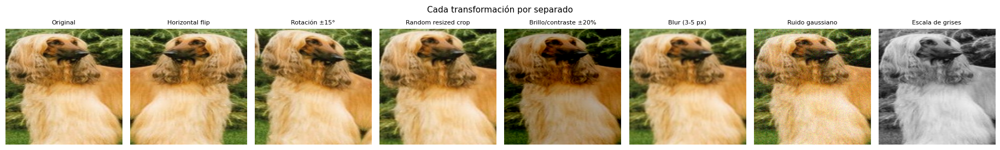

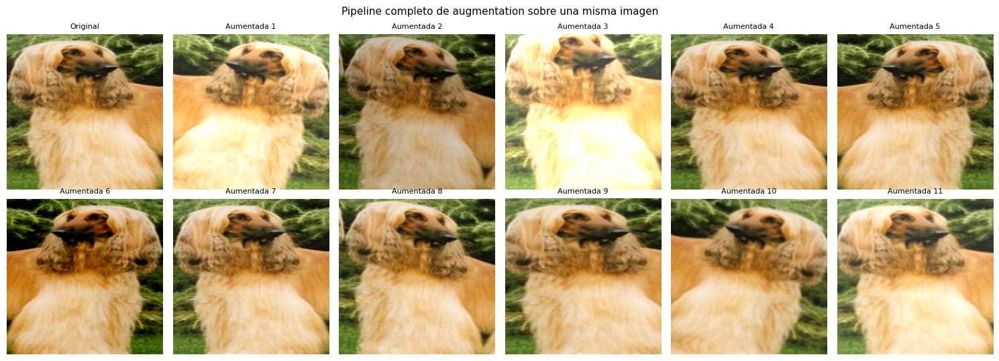

In [33]:
import albumentations as A
importlib.reload(prep)

base = prep.to_rgb_resized(cv2.imread(str(limpio[limpio["split"] == "train"].iloc[0]["path"])), IMG)

# 1) Cada transformación por separado (con p=1 para que siempre se aplique)
individuales = {
    "Original": None,
    "Horizontal flip": A.HorizontalFlip(p=1),
    "Rotación ±15°": A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT_101, p=1),
    "Random resized crop": A.RandomResizedCrop(size=(IMG, IMG), scale=(0.75, 1.0), ratio=(0.75, 1.33), p=1),
    "Brillo/contraste ±20%": A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1),
    "Blur (3-5 px)": A.GaussianBlur(blur_limit=(3, 5), p=1),
    "Ruido gaussiano": A.GaussNoise(std_range=(0.02, 0.06), p=1),
    "Escala de grises": A.ToGray(p=1),
}
fig, axes = plt.subplots(1, len(individuales), figsize=(2.3 * len(individuales), 2.8))
for ax, (nombre, t) in zip(axes, individuales.items()):
    ax.imshow(base if t is None else t(image=base)["image"])
    ax.set_title(nombre, fontsize=8)
    ax.axis("off")
plt.suptitle("Cada transformación por separado", fontsize=11)
plt.tight_layout()
plt.show()

# 2) El pipeline completo aplicado 12 veces a la misma imagen (cada vez sale distinto)
aug = prep.train_augmentation(IMG)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(base if i == 0 else aug(image=base)["image"])
    ax.set_title("Original" if i == 0 else f"Aumentada {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Pipeline completo de augmentation sobre una misma imagen", fontsize=11)
plt.tight_layout()
plt.show()

**Data augmentation (solo train)** — implementado en `train_augmentation` de `src/lib/preprocessing.py`.
Se aplica sobre la imagen RGB ya redimensionada y antes de normalizar; nunca sobre valid, test ni el
conjunto independiente.

| Transformación      | Rango                                            | Justificación                                                                                                                                           |
| ------------------- | ------------------------------------------------ | ------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Horizontal flip     | p = 0,5                                          | Un perro espejado es de la misma raza. El flip vertical no se usa: no ocurre en fotos reales                                                            |
| Rotación            | ±15°, bordes reflejados                          | Cámara levemente inclinada. Sin rotaciones de 90°. El borde reflejado evita esquinas negras                                                             |
| Random resized crop | 75–100 % del área, proporción 3:4 a 4:3, p = 0,5 | Simula los recortes de YOLO de la Etapa 3: otro encuadre, partes cortadas y proporciones no cuadradas estiradas a 224 (cambio de dominio medido en 6.4) |
| Brillo y contraste  | ±20 %, p = 0,5                                   | El brillo del dataset varía ≈ ±12 % del rango (6.4); ±20 % cubre esa variación sin generar exposiciones extremas, que no existen en los datos           |
| Blur gaussiano      | kernel 3–5 px, p = 0,2                           | Coherente con conservar las imágenes moderadamente borrosas (regla 3). Kernel chico para no borrar la textura del pelaje                                |
| Ruido gaussiano     | desvío 2–6 %, p = 0,2                            | Ruido de cámara y de fotos con poca luz                                                                                                                 |
| Escala de grises    | p = 0,05                                         | El 0,3 % del dataset está en blanco y negro (6.2). Probabilidad baja porque el color del pelaje es una pista importante de la raza                      |

**Transformaciones descartadas:** flip vertical, rotaciones de 90° y cambios de tono (hue): alteran la
raza aparente o no ocurren en la realidad. El augmentation no se usa para compensar el desbalance, que es
moderado (6.1); esa alternativa se evalúa en la Etapa 2 (class weights / weighted sampling).


## 11. Splits

TO-DO: definir train / validation / test (los del dataset o redefinidos, justificando), verificar
que no haya fuga de datos entre splits, fijar semillas y guardar los splits finales (CSV/JSON con
rutas y etiquetas) para `2-train.ipynb`.


In [34]:
SPLITS_CSV = settings.data_path / "splits.csv"
DESCARTADAS_CSV = settings.data_path / "descartadas.csv"


def ruta_relativa(p):
    """Ruta relativa a DATASET_PATH: el mismo CSV sirve en local, Colab y Docker."""
    return Path(p).relative_to(settings.dataset_path).as_posix()


def corr_imagenes(a, b, s=64):
    """Correlación entre dos imágenes reducidas a 64x64 en grises (misma medida que la regla 5)."""
    ga, gb = (cv2.resize(cv2.imread(str(x), cv2.IMREAD_GRAYSCALE), (s, s), interpolation=cv2.INTER_AREA)
              .astype(np.float32).ravel() for x in (a, b))
    return float(np.corrcoef(ga, gb)[0, 1])


# 1) Dataset filtrado
final = df[~df["descartar"]].copy()
final["path_rel"] = final["path"].map(ruta_relativa)

# 2) Conjunto independiente: solo las imágenes limpias (las escenas y sin perros son para la Etapa 3)
fuentes = pd.read_csv(FUENTES)
ind = fuentes[fuentes["tipo"] == "limpia"].copy()
ind["path_rel"] = "independent/" + ind["archivo"]
ind["breed"] = ind["raza"]
ind["split"] = "independent"

# 3) Verificación de fuga de datos
assert final["path_rel"].is_unique, "Hay una imagen en más de un split"
assert final.groupby("cluster_dup")["split"].nunique().max() == 1, "Hay duplicados repartidos entre splits"
print("✔ Ninguna imagen ni duplicado del dataset aparece en más de un split")

# Conjunto independiente vs dataset: misma detección que la regla 5 (dHash + correlación)
hash_ind = np.array([dhash(settings.dataset_path / p) for p in ind["path_rel"]], dtype=np.uint64)
dist = np.bitwise_count(hash_ind[:, None] ^ final["dhash"].to_numpy()[None, :])
fugas = []
for i, j in np.argwhere(dist <= 10):
    c = corr_imagenes(settings.dataset_path / ind["path_rel"].iloc[i], final["path"].iloc[j])
    if dist[i, j] == 0 or c >= 0.90:
        fugas.append((ind.index[i], final["path_rel"].iloc[j], int(dist[i, j]), round(c, 3)))
print(f"Imágenes del conjunto independiente que ya estaban en el dataset: {len(fugas)}")
if fugas:
    display(pd.DataFrame(fugas, columns=["fila_ind", "copia_en_dataset", "dist", "corr"]))
    ind = ind.drop(index=[f[0] for f in fugas])  # no son independientes: se excluyen

# 4) Guardar
splits = pd.concat([final[["path_rel", "breed", "split"]], ind[["path_rel", "breed", "split"]]],
                   ignore_index=True).rename(columns={"path_rel": "path"})
splits.to_csv(SPLITS_CSV, index=False)

descartadas = df[df["descartar"]].copy()
descartadas["path"] = descartadas["path"].map(ruta_relativa)
descartadas["reglas"] = descartadas[list(REGLAS)].apply(
    lambda fila: ", ".join(REGLAS[c] for c in REGLAS if fila[c]), axis=1)
descartadas[["path", "breed", "split", "reglas"]].to_csv(DESCARTADAS_CSV, index=False)

print(f"\nGuardado {SPLITS_CSV} y {DESCARTADAS_CSV}")
display(splits["split"].value_counts().reindex(SPLITS + ["independent"]).rename("imágenes"))
print("Razas por split:", splits.groupby("split")["breed"].nunique().to_dict())

✔ Ninguna imagen ni duplicado del dataset aparece en más de un split
Imágenes del conjunto independiente que ya estaban en el dataset: 2


,fila_ind,copia_en_dataset,dist,corr
0,48,train/Malinois/004.jpg,3,0.968
1,100,train/Collie/052.jpg,1,1.000



Guardado data\splits.csv y data\descartadas.csv


split
train          7652
valid           685
test            696
independent     184
Name: imágenes, dtype: int64

Razas por split: {'independent': 22, 'test': 70, 'train': 70, 'valid': 70}


## 12. Resumen final

TO-DO: tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.


In [36]:
fuentes = pd.read_csv(FUENTES)

tabla = splits.groupby("split").agg(razas=("breed", "nunique"), imágenes=("path", "size"))
por_raza = splits.groupby(["split", "breed"]).size().groupby("split").agg(["min", "median", "max"])
por_raza.columns = ["mín por raza", "mediana por raza", "máx por raza"]
tabla = tabla.join(por_raza).reindex(SPLITS + ["independent"])
display(tabla)

extra = fuentes[fuentes["tipo"] != "limpia"]["tipo"].value_counts()
print("Conjunto independiente para la Etapa 3:", extra.to_dict())

,razas,imágenes,mín por raza,mediana por raza,máx por raza
split,,,,,
train,70,7652,63,107.5,190
valid,70,685,8,10.0,10
test,70,696,8,10.0,10
independent,22,184,5,9.0,10


Conjunto independiente para la Etapa 3: {'sin_perro': 21, 'escena': 16}


**Resumen:** el dataset queda con 70 razas en train, valid y test (7652 / 685 / 696 imágenes tras el
filtrado) y un conjunto independiente de 22 razas con imágenes limpias para las Etapas 1 y 2, más escenas
con varios perros e imágenes sin perros para la Etapa 3. Los splits están guardados en `data/splits.csv`
y las imágenes descartadas, con su motivo, en `data/descartadas.csv`.


## 13. Licencias y uso de imágenes

TO-DO: licencia del dataset, fuente y licencia de las imágenes del conjunto independiente y criterio
aplicado a imágenes con personas identificables.


In [37]:
print("Licencias del conjunto independiente:")
display(fuentes["licencia"].value_counts().rename("imágenes"))
print("Imágenes sin autor registrado:", int(fuentes["autor"].isna().sum() + (fuentes["autor"] == "").sum()))

Licencias del conjunto independiente:


licencia
CC BY-SA 4.0       102
CC BY 2.0           31
CC BY-SA 3.0        29
CC0                 19
Public domain       14
CC BY 4.0            9
CC BY-SA 2.0         8
CC BY 3.0            7
CC BY-SA 2.5         2
CC BY-SA 2.0 tw      1
CC BY 2.5            1
Name: imágenes, dtype: int64

Imágenes sin autor registrado: 3


# 13. Licencias y uso de imágenes

**Dataset (70 Dog Breeds Image Dataset, Kaggle):** su licencia figura en la página del dataset
(https://www.kaggle.com/datasets/gpiosenka/70-dog-breedsimage-data-set). Según su autor, las imágenes se
obtuvieron mediante búsquedas en internet, por lo que los derechos de cada foto pertenecen a sus autores
originales. Por eso se usa únicamente con fines académicos, sin fines comerciales, y no se redistribuye:
`data/dataset/*` está excluido del repositorio por el `.gitignore`.

**Conjunto independiente:** todas las imágenes provienen de Wikimedia Commons y se descargaron solo si
tenían licencia Creative Commons o de dominio público (ver tabla). De cada imagen se registró en
`data/dataset/independent/fuentes.csv` la URL de origen, el autor y la licencia, lo que cumple con el
requisito de atribución de las licencias CC BY y CC BY-SA. Tampoco se suben al repositorio: se comparten
con los docentes mediante un link de solo lectura.

**Personas identificables:** en la revisión manual se descartaron las imágenes con personas identificables
en primer plano. En las escenas de la Etapa 3 solo se conservaron imágenes donde las personas aparecen
lejos o sin el rostro visible. Las imágenes no se publican fuera del ámbito del TP.
